# Nextflow Trace File Analysis
Analysing per-task execution metrics from Nextflow trace files across four experiment setups:
- **S1**: 2 concurrent users, no reuse
- **S2-seq**: 2 sequential users, full artifact reuse (resume)
- **S2**: 2 concurrent users, shared genome index reuse
- **S3**: 2 concurrent users, pod-service reuse

Each trace file contains one row per task with: duration, realtime, %cpu, peak_rss, peak_vmem, rchar, wchar

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

METRICS_PATH = '/home/sm/experiments/metrics'

# Map experiment label -> (user1_dir, user2_dir)
EXPERIMENTS = {
    'S1: No Reuse':        ('user1_20260313_155703',          'user2_20260313_155703'),
    'S2-seq: Full Reuse':  ('user1_20260317_135922',          'user2_20260317_135922'),
    'S2: Index Reuse':     ('user1_reuse_20260320_114138',    'user2_reuse_20260320_114138'),
    'S3: Pod-Service':     ('user1_podservice_20260330_160150','user2_podservice_20260330_160150'),
}

COLORS = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
EXP_COLORS = dict(zip(EXPERIMENTS.keys(), COLORS))
USER_COLORS = {'user1': '#2980b9', 'user2': '#c0392b'}

def parse_duration(s):
    """Parse Nextflow duration string like '1m 23s', '45.3s', '2h 3m' to seconds."""
    if pd.isna(s) or s == '-':
        return 0.0
    s = str(s).strip()
    total = 0.0
    for val, unit in re.findall(r'([\d.]+)\s*(ms|s|m|h|d)', s):
        val = float(val)
        if unit == 'ms': total += val / 1000
        elif unit == 's': total += val
        elif unit == 'm': total += val * 60
        elif unit == 'h': total += val * 3600
        elif unit == 'd': total += val * 86400
    return total

def parse_memory(s):
    """Parse memory string like '512 MB', '1.2 GB' to bytes."""
    if pd.isna(s) or s == '-':
        return 0.0
    s = str(s).strip()
    m = re.search(r'([\d.]+)\s*(KB|MB|GB|TB|B)', s, re.IGNORECASE)
    if not m:
        return 0.0
    val, unit = float(m.group(1)), m.group(2).upper()
    multipliers = {'B': 1, 'KB': 1024, 'MB': 1024**2, 'GB': 1024**3, 'TB': 1024**4}
    return val * multipliers.get(unit, 1)

def load_trace(dirpath):
    """Load and parse a Nextflow trace.txt file."""
    path = os.path.join(METRICS_PATH, dirpath, 'trace.txt')
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path, sep='\t')
    if df.empty:
        return None
    
    # Parse durations
    for col in ['duration', 'realtime']:
        if col in df.columns:
            df[col + '_sec'] = df[col].apply(parse_duration)
    
    # Parse memory
    for col in ['peak_rss', 'peak_vmem']:
        if col in df.columns:
            df[col + '_bytes'] = df[col].apply(parse_memory)
            df[col + '_mb'] = df[col + '_bytes'] / (1024**2)
    
    # Parse CPU %
    if '%cpu' in df.columns:
        df['cpu_pct'] = pd.to_numeric(df['%cpu'].astype(str).str.replace('%',''), errors='coerce')
    
    # Extract pipeline step name from task name
    if 'name' in df.columns:
        df['step'] = df['name'].apply(lambda x: str(x).split(':')[-1].split(' ')[0] if pd.notna(x) else 'UNKNOWN')
        df['subworkflow'] = df['name'].apply(lambda x: str(x).split(':')[1] if pd.notna(x) and len(str(x).split(':')) > 1 else 'OTHER')
    
    # Parse rchar/wchar (disk I/O)
    for col in ['rchar', 'wchar']:
        if col in df.columns:
            df[col + '_bytes'] = df[col].apply(parse_memory)
            df[col + '_mb'] = df[col + '_bytes'] / (1024**2)
    
    # Only keep completed tasks
    if 'status' in df.columns:
        df = df[df['status'] == 'COMPLETED'].copy()
    
    return df

# Load all traces
traces = {}
for exp_label, (u1_dir, u2_dir) in EXPERIMENTS.items():
    df1 = load_trace(u1_dir)
    df2 = load_trace(u2_dir)
    if df1 is not None:
        df1['user'] = 'user1'
    if df2 is not None:
        df2['user'] = 'user2'
    
    parts = [d for d in [df1, df2] if d is not None]
    if parts:
        combined = pd.concat(parts, ignore_index=True)
        combined['experiment'] = exp_label
        traces[exp_label] = combined
        print(f'{exp_label}: {len(combined)} tasks ({len(df1) if df1 is not None else 0} user1, {len(df2) if df2 is not None else 0} user2)')
    else:
        print(f'{exp_label}: NO DATA')

# Combined dataframe
all_traces = pd.concat(traces.values(), ignore_index=True)
print(f'\nTotal tasks loaded: {len(all_traces)}')
print(f'Columns: {list(all_traces.columns)}')

S1: No Reuse: 438 tasks (219 user1, 219 user2)
S2-seq: Full Reuse: 220 tasks (219 user1, 1 user2)
S2: Index Reuse: 434 tasks (217 user1, 217 user2)
S3: Pod-Service: 438 tasks (219 user1, 219 user2)

Total tasks loaded: 1530
Columns: ['task_id', 'hash', 'native_id', 'name', 'status', 'exit', 'submit', 'duration', 'realtime', '%cpu', 'peak_rss', 'peak_vmem', 'rchar', 'wchar', 'duration_sec', 'realtime_sec', 'peak_rss_bytes', 'peak_rss_mb', 'peak_vmem_bytes', 'peak_vmem_mb', 'cpu_pct', 'step', 'subworkflow', 'rchar_bytes', 'rchar_mb', 'wchar_bytes', 'wchar_mb', 'user', 'experiment']


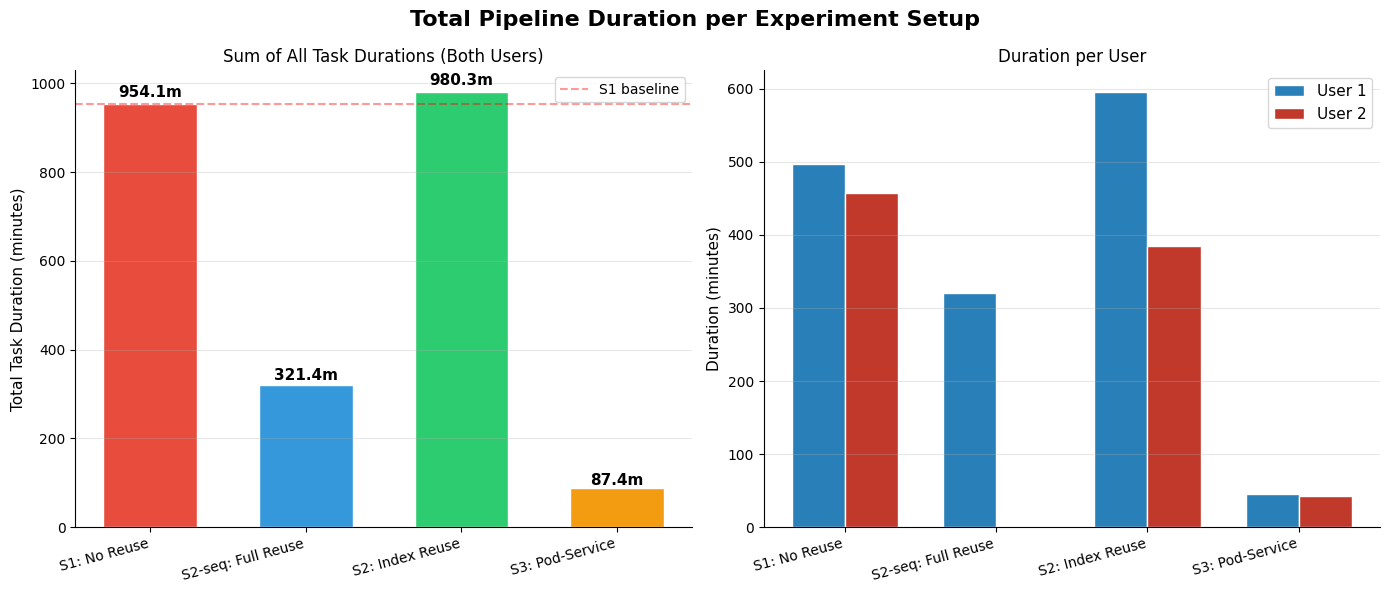

In [2]:
# ── Plot 1: Total Wall-Clock Duration per Experiment ──────────────────
# Sum of all task durations — shows total pipeline compute time

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Total Pipeline Duration per Experiment Setup', fontsize=16, fontweight='bold')

# Left: total duration summed across both users
ax = axes[0]
totals = []
labels = []
for exp_label, df in traces.items():
    totals.append(df['duration_sec'].sum() / 60)  # minutes
    labels.append(exp_label)

bars = ax.bar(range(len(labels)), totals, color=COLORS[:len(labels)], edgecolor='white', width=0.6)
for bar, val in zip(bars, totals):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height()*1.01,
            f'{val:.1f}m', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=10, rotation=15, ha='right')
ax.set_ylabel('Total Task Duration (minutes)', fontsize=11)
ax.set_title('Sum of All Task Durations (Both Users)', fontsize=12)
ax.axhline(y=totals[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Right: per-user breakdown
ax2 = axes[1]
x = np.arange(len(labels))
width = 0.35
u1_totals = [traces[e][traces[e]['user']=='user1']['duration_sec'].sum()/60 for e in traces]
u2_totals = [traces[e][traces[e]['user']=='user2']['duration_sec'].sum()/60 for e in traces]

ax2.bar(x - width/2, u1_totals, width, label='User 1', color='#2980b9', edgecolor='white')
ax2.bar(x + width/2, u2_totals, width, label='User 2', color='#c0392b', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10, rotation=15, ha='right')
ax2.set_ylabel('Duration (minutes)', fontsize=11)
ax2.set_title('Duration per User', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/trace_plot1_duration.png', dpi=150, bbox_inches='tight')
plt.show()

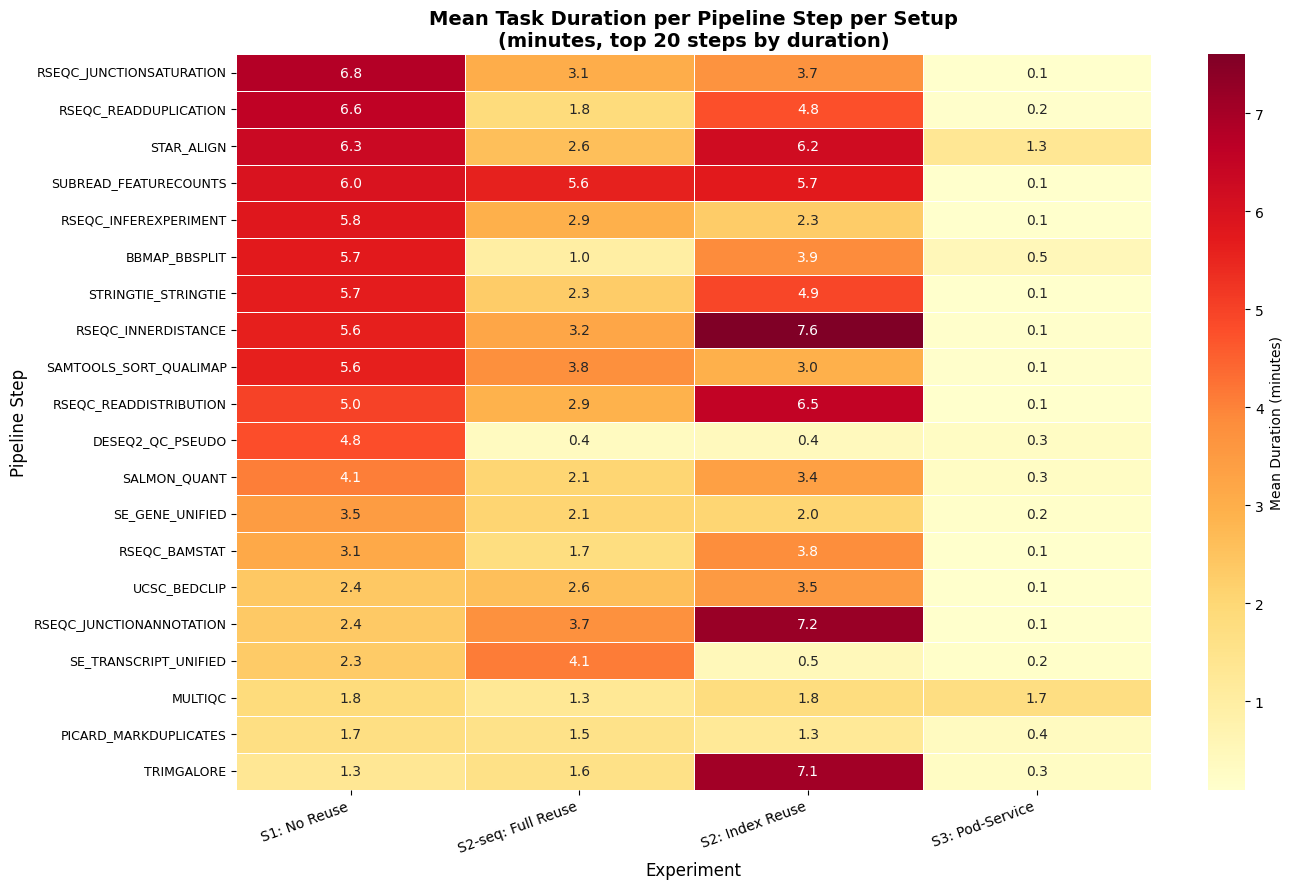

In [3]:
# ── Plot 2: Duration per Pipeline Step (heatmap) ──────────────────────
# Shows which steps take longer/shorter in each setup

# Get top steps by average duration
top_steps = (all_traces.groupby('step')['duration_sec']
             .mean().sort_values(ascending=False).head(20).index.tolist())

# Build pivot: step x experiment = mean duration (seconds)
pivot = all_traces[all_traces['step'].isin(top_steps)].groupby(
    ['step', 'experiment'])['duration_sec'].mean().unstack(fill_value=0)

# Sort by S1 duration
if 'S1: No Reuse' in pivot.columns:
    pivot = pivot.sort_values('S1: No Reuse', ascending=False)

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(pivot / 60,  # minutes
            annot=True, fmt='.1f', cmap='YlOrRd',
            ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Mean Duration (minutes)'})
ax.set_title('Mean Task Duration per Pipeline Step per Setup\n(minutes, top 20 steps by duration)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Experiment', fontsize=12)
ax.set_ylabel('Pipeline Step', fontsize=12)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('/tmp/trace_plot2_step_duration_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

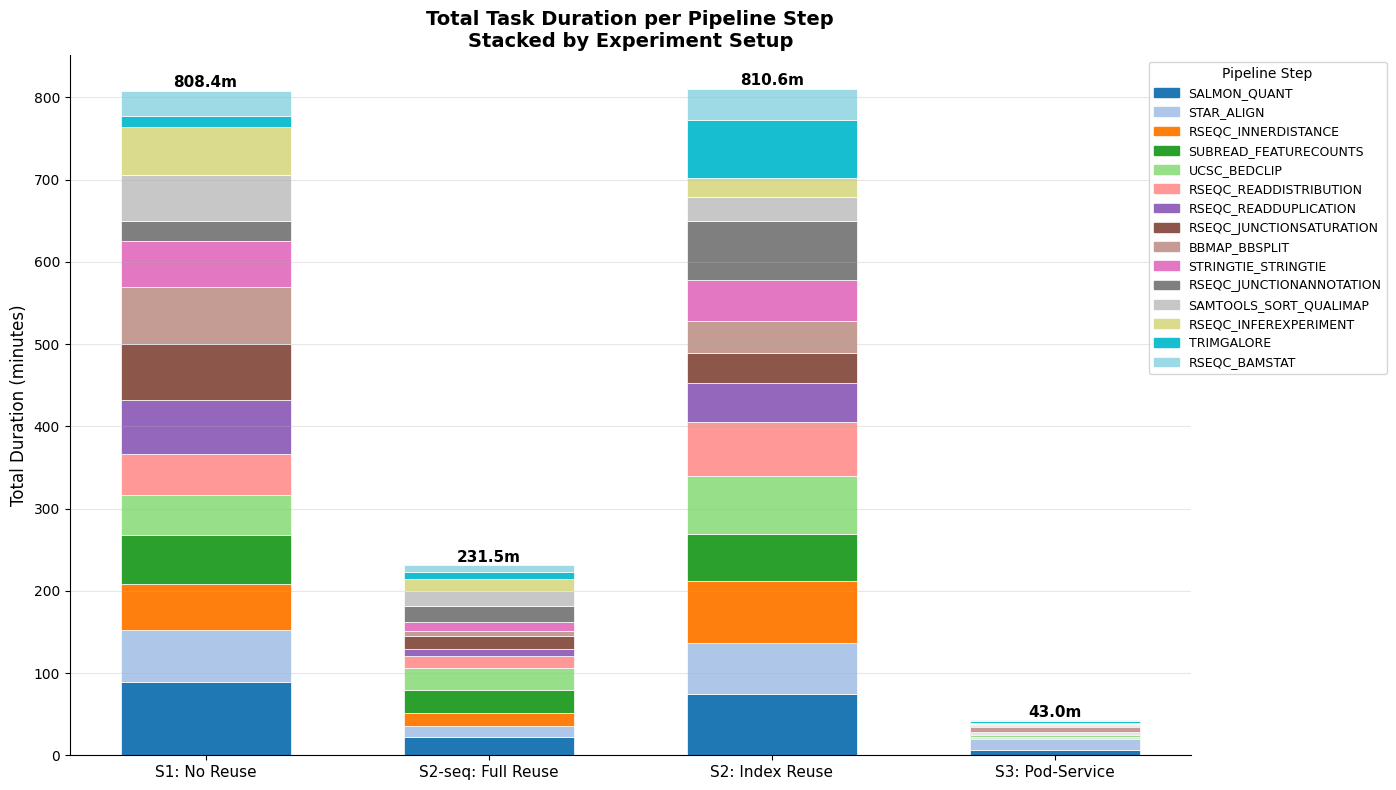

In [4]:
# ── Plot 3: Stacked Bar — Total Duration per Step per Experiment ───────
# Shows how time distributes across pipeline steps

top_steps_duration = (all_traces.groupby('step')['duration_sec']
                      .sum().sort_values(ascending=False).head(15).index.tolist())

step_colors = plt.cm.tab20(np.linspace(0, 1, len(top_steps_duration)))
step_color_map = dict(zip(top_steps_duration, step_colors))

fig, ax = plt.subplots(figsize=(14, 8))

exp_labels = list(traces.keys())
x = np.arange(len(exp_labels))
bottoms = np.zeros(len(exp_labels))
patches = []

for step in top_steps_duration:
    vals = []
    for exp_label in exp_labels:
        df = traces[exp_label]
        v = df[df['step'] == step]['duration_sec'].sum() / 60
        vals.append(v)
    vals = np.array(vals)
    if vals.sum() > 0:
        color = step_color_map[step]
        ax.bar(x, vals, width=0.6, bottom=bottoms, color=color, edgecolor='white', linewidth=0.5)
        bottoms += vals
        patches.append(mpatches.Patch(color=color, label=step))

for i, total in enumerate(bottoms):
    ax.text(i, total + 0.5, f'{total:.1f}m', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(exp_labels, fontsize=11)
ax.set_ylabel('Total Duration (minutes)', fontsize=12)
ax.set_title('Total Task Duration per Pipeline Step\nStacked by Experiment Setup',
             fontsize=14, fontweight='bold')
ax.legend(handles=patches, loc='upper right', bbox_to_anchor=(1.18, 1),
          fontsize=9, title='Pipeline Step')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/trace_plot3_stacked_duration.png', dpi=150, bbox_inches='tight')
plt.show()

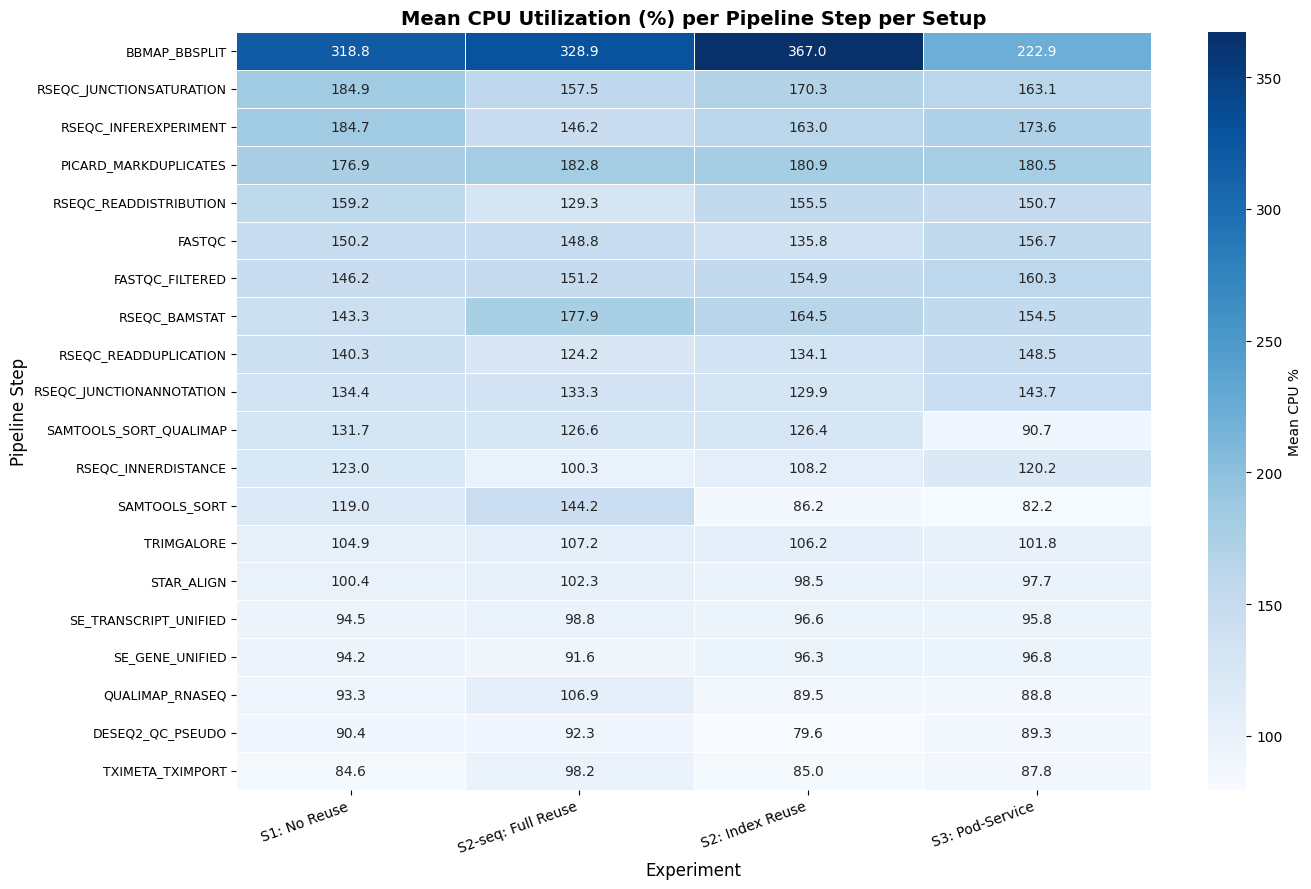

In [5]:
# ── Plot 4: CPU Utilization per Step per Experiment ────────────────────
# Shows which steps use more/less CPU across setups

top_steps_cpu = (all_traces.groupby('step')['cpu_pct']
                 .mean().sort_values(ascending=False).head(20).index.tolist())

pivot_cpu = all_traces[all_traces['step'].isin(top_steps_cpu)].groupby(
    ['step', 'experiment'])['cpu_pct'].mean().unstack(fill_value=0)

if 'S1: No Reuse' in pivot_cpu.columns:
    pivot_cpu = pivot_cpu.sort_values('S1: No Reuse', ascending=False)

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(pivot_cpu,
            annot=True, fmt='.1f', cmap='Blues',
            ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Mean CPU %'})
ax.set_title('Mean CPU Utilization (%) per Pipeline Step per Setup',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Experiment', fontsize=12)
ax.set_ylabel('Pipeline Step', fontsize=12)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('/tmp/trace_plot4_cpu_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

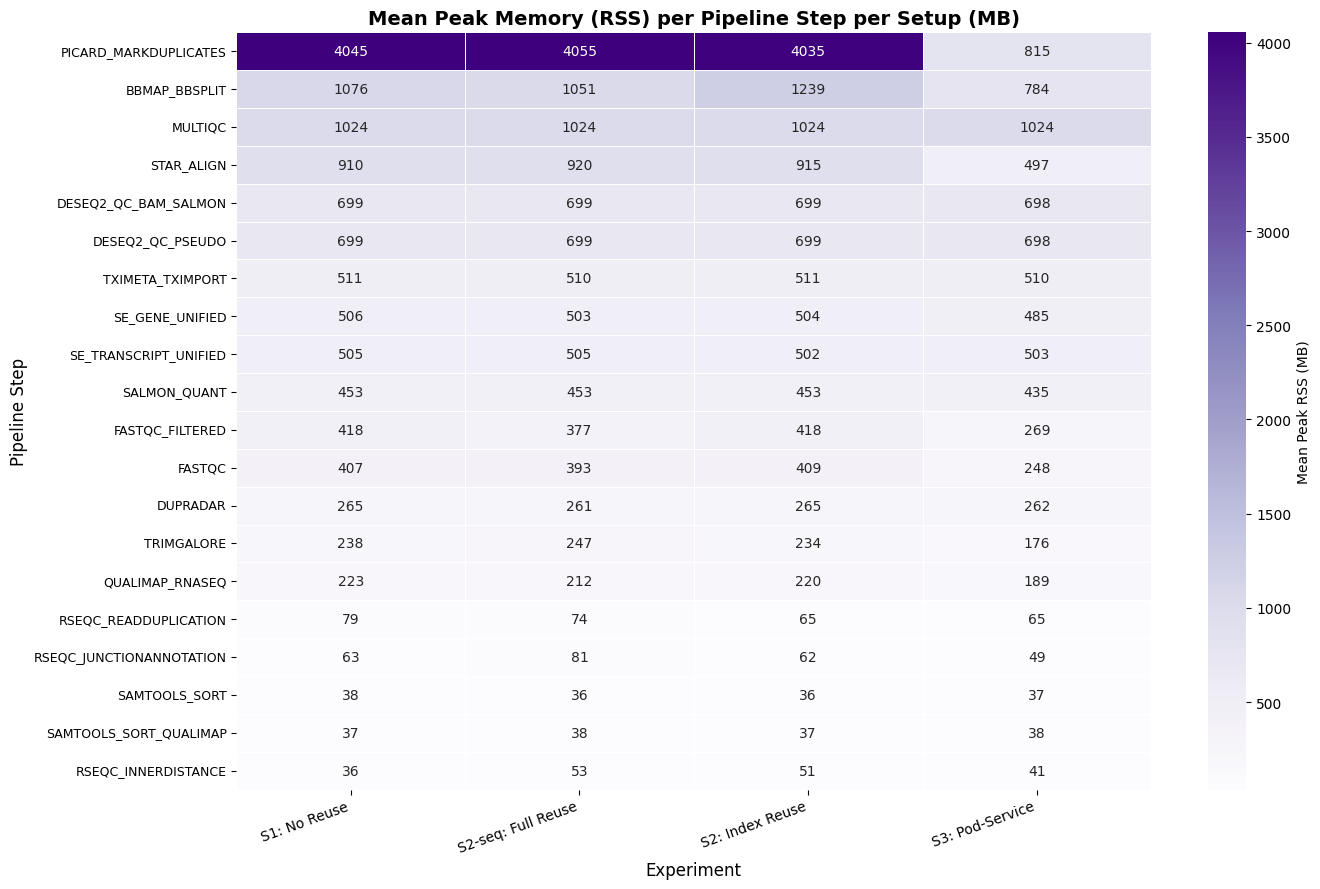

In [6]:
# ── Plot 5: Memory Usage per Step per Experiment ──────────────────────

top_steps_mem = (all_traces.groupby('step')['peak_rss_mb']
                 .mean().sort_values(ascending=False).head(20).index.tolist())

pivot_mem = all_traces[all_traces['step'].isin(top_steps_mem)].groupby(
    ['step', 'experiment'])['peak_rss_mb'].mean().unstack(fill_value=0)

if 'S1: No Reuse' in pivot_mem.columns:
    pivot_mem = pivot_mem.sort_values('S1: No Reuse', ascending=False)

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(pivot_mem,
            annot=True, fmt='.0f', cmap='Purples',
            ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Mean Peak RSS (MB)'})
ax.set_title('Mean Peak Memory (RSS) per Pipeline Step per Setup (MB)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Experiment', fontsize=12)
ax.set_ylabel('Pipeline Step', fontsize=12)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('/tmp/trace_plot5_memory_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

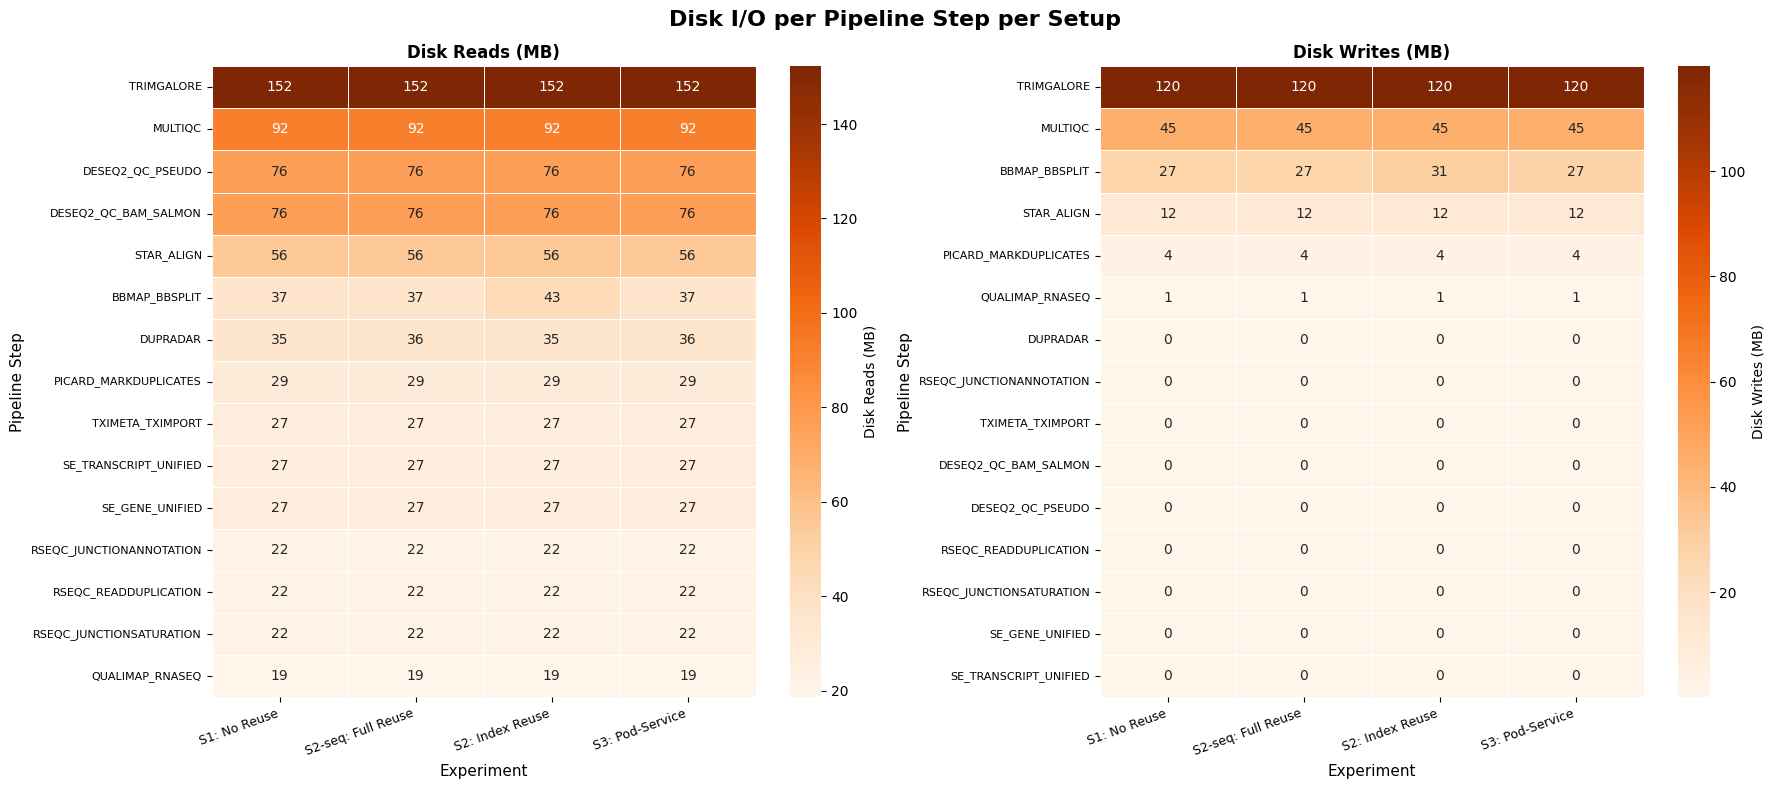

In [7]:
# ── Plot 6: Disk I/O per Step per Experiment ──────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Disk I/O per Pipeline Step per Setup', fontsize=16, fontweight='bold')

top_steps_io = (all_traces.groupby('step')['rchar_mb']
                .mean().sort_values(ascending=False).head(15).index.tolist())

for ax, (col, title) in zip(axes, [('rchar_mb', 'Disk Reads (MB)'), ('wchar_mb', 'Disk Writes (MB)')]):
    pivot_io = all_traces[all_traces['step'].isin(top_steps_io)].groupby(
        ['step', 'experiment'])[col].mean().unstack(fill_value=0)
    if 'S1: No Reuse' in pivot_io.columns:
        pivot_io = pivot_io.sort_values('S1: No Reuse', ascending=False)
    sns.heatmap(pivot_io, annot=True, fmt='.0f', cmap='Oranges',
                ax=ax, linewidths=0.5,
                cbar_kws={'label': title})
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Experiment', fontsize=11)
    ax.set_ylabel('Pipeline Step', fontsize=11)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)
    plt.setp(ax.get_yticklabels(), fontsize=8)

plt.tight_layout()
plt.savefig('/tmp/trace_plot6_disk_io_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

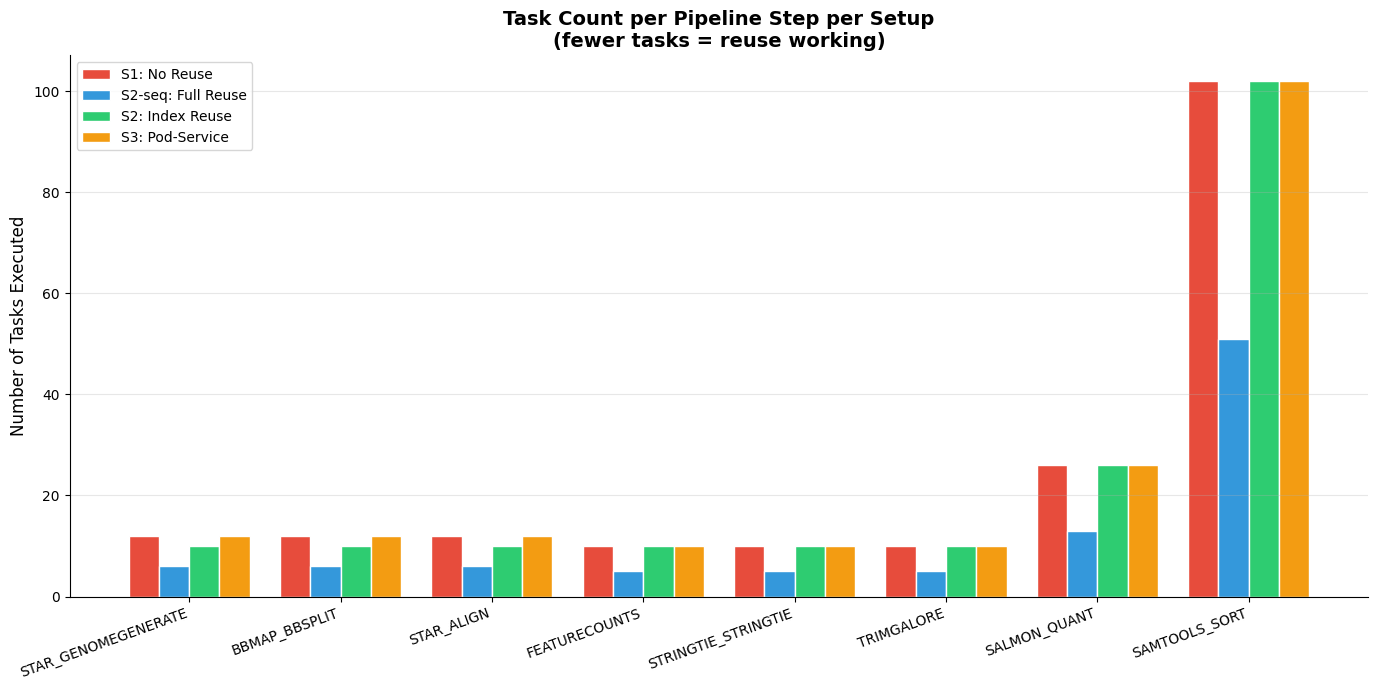

In [8]:
# ── Plot 7: Task Count per Step — shows reuse effect ──────────────────
# In S2-seq, User 2 tasks are CACHED so count drops to ~0
# In S2, STAR/BBSPLIT tasks should appear only once (shared)
# In S3, FEATURECOUNTS/STRINGTIE tasks should be 0 (replaced by service calls)

key_steps = [
    'STAR_GENOMEGENERATE', 'BBMAP_BBSPLIT', 'STAR_ALIGN',
    'FEATURECOUNTS', 'STRINGTIE_STRINGTIE', 'TRIMGALORE',
    'SALMON_QUANT', 'SAMTOOLS_SORT',
]

# Count tasks per step per experiment
count_data = {}
for exp_label, df in traces.items():
    counts = {}
    for step in key_steps:
        counts[step] = len(df[df['step'].str.contains(step.split('_')[0], case=False, na=False)])
    count_data[exp_label] = counts

count_df = pd.DataFrame(count_data).T
# Drop columns with all zeros
count_df = count_df.loc[:, (count_df != 0).any(axis=0)]

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(count_df.columns))
width = 0.2
offsets = np.linspace(-width*1.5, width*1.5, len(count_df))

for i, (exp_label, row) in enumerate(count_df.iterrows()):
    ax.bar(x + offsets[i], row.values, width, label=exp_label,
           color=EXP_COLORS[exp_label], edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(count_df.columns, fontsize=10, rotation=20, ha='right')
ax.set_ylabel('Number of Tasks Executed', fontsize=12)
ax.set_title('Task Count per Pipeline Step per Setup\n(fewer tasks = reuse working)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/trace_plot7_task_counts.png', dpi=150, bbox_inches='tight')
plt.show()

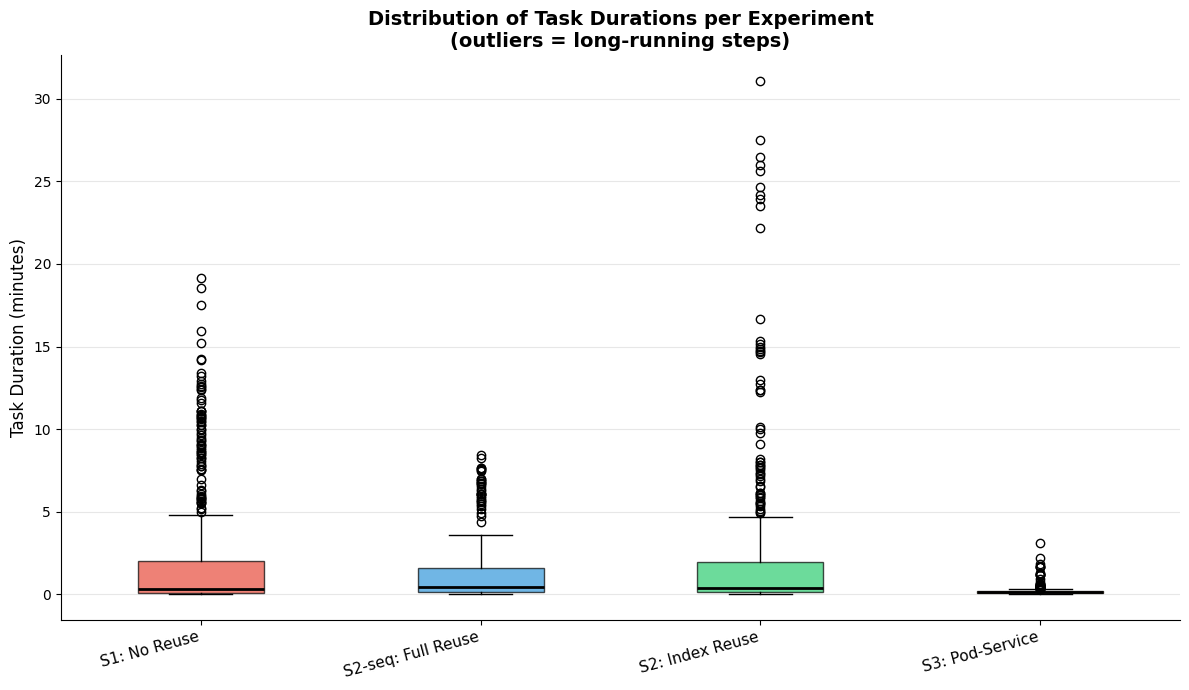

In [9]:
# ── Plot 8: Box Plot — Duration Distribution per Experiment ───────────
# Shows spread and outliers of task durations

fig, ax = plt.subplots(figsize=(12, 7))

plot_data = [traces[e]['duration_sec'].dropna() / 60 for e in traces]
bp = ax.boxplot(plot_data, patch_artist=True, notch=False,
                medianprops=dict(color='black', linewidth=2))

for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_xticklabels(list(traces.keys()), fontsize=11, rotation=15, ha='right')
ax.set_ylabel('Task Duration (minutes)', fontsize=12)
ax.set_title('Distribution of Task Durations per Experiment\n(outliers = long-running steps)',
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/trace_plot8_duration_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

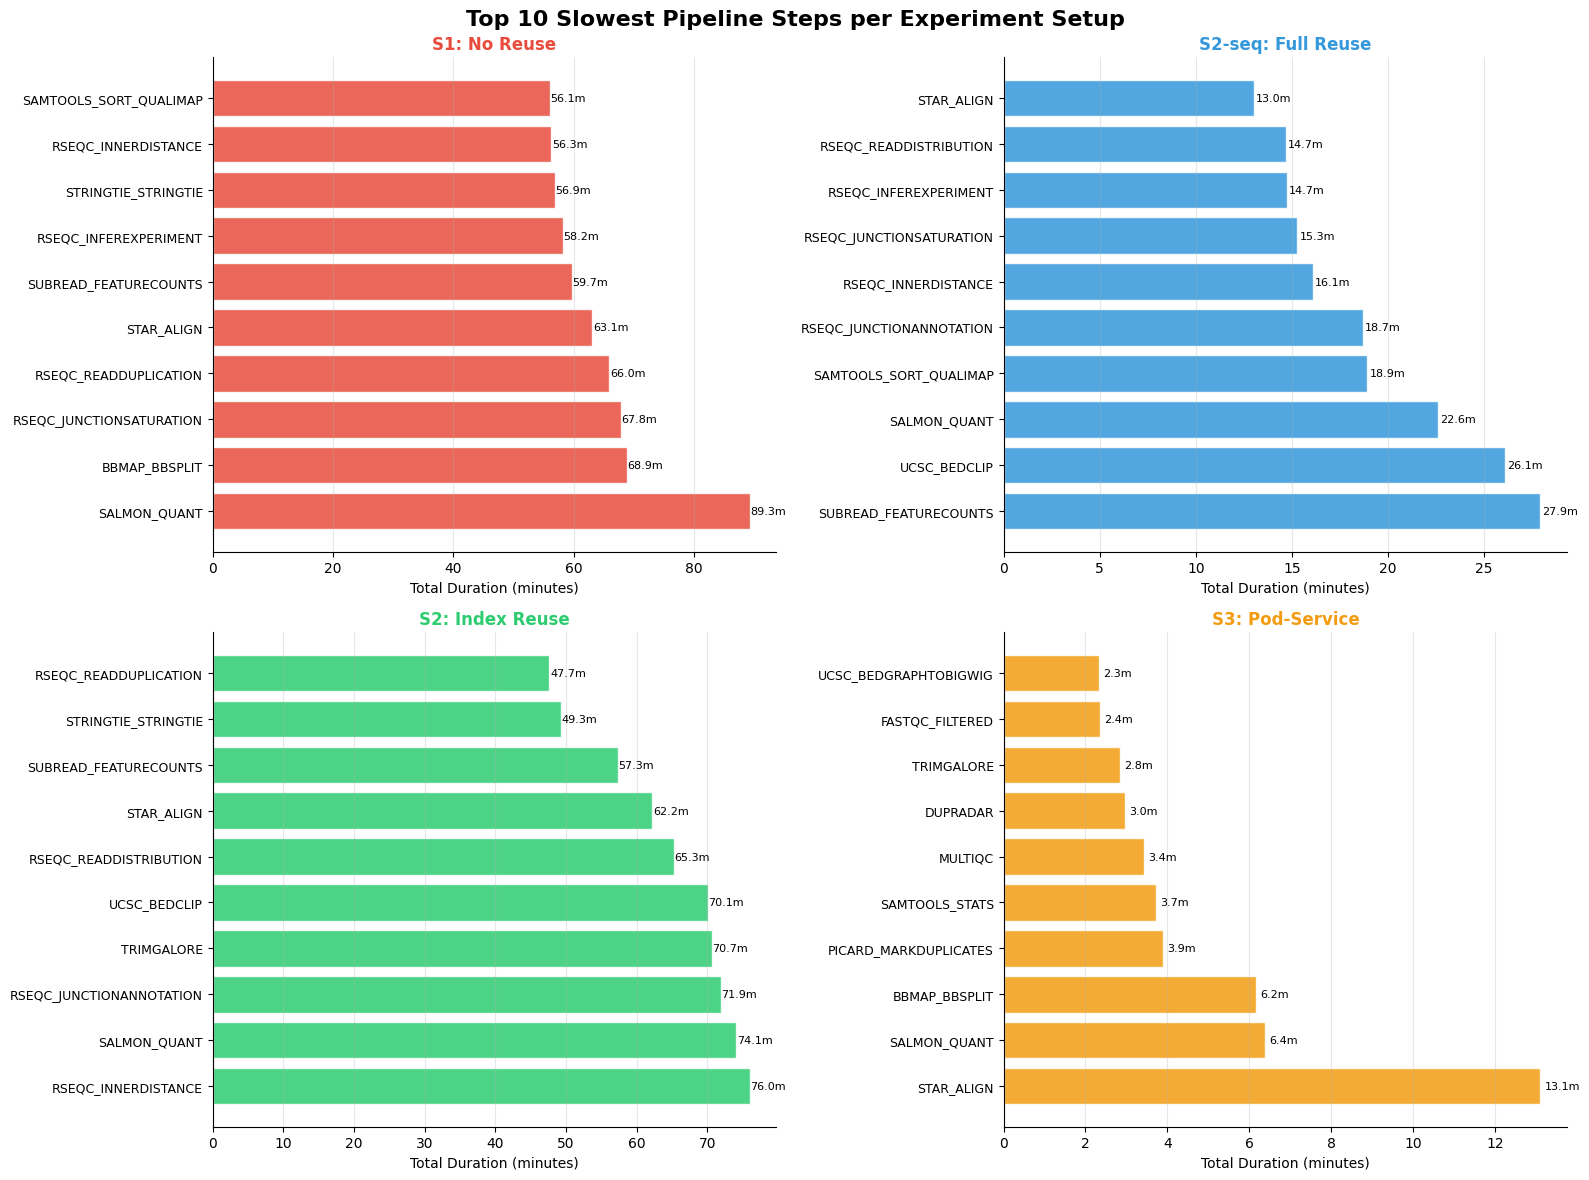

In [10]:
# ── Plot 9: Top 10 Slowest Steps — bar chart ──────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Top 10 Slowest Pipeline Steps per Experiment Setup',
             fontsize=16, fontweight='bold')
axes_flat = axes.flatten()

for ax, (exp_label, df) in zip(axes_flat, traces.items()):
    top = (df.groupby('step')['duration_sec'].sum()
           .sort_values(ascending=False).head(10) / 60)
    
    bars = ax.barh(range(len(top)), top.values,
                   color=EXP_COLORS[exp_label], edgecolor='white', alpha=0.85)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index, fontsize=9)
    ax.set_xlabel('Total Duration (minutes)', fontsize=10)
    ax.set_title(exp_label, fontsize=12, fontweight='bold',
                color=EXP_COLORS[exp_label])
    ax.grid(axis='x', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    for bar, val in zip(bars, top.values):
        ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}m', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('/tmp/trace_plot9_slowest_steps.png', dpi=150, bbox_inches='tight')
plt.show()

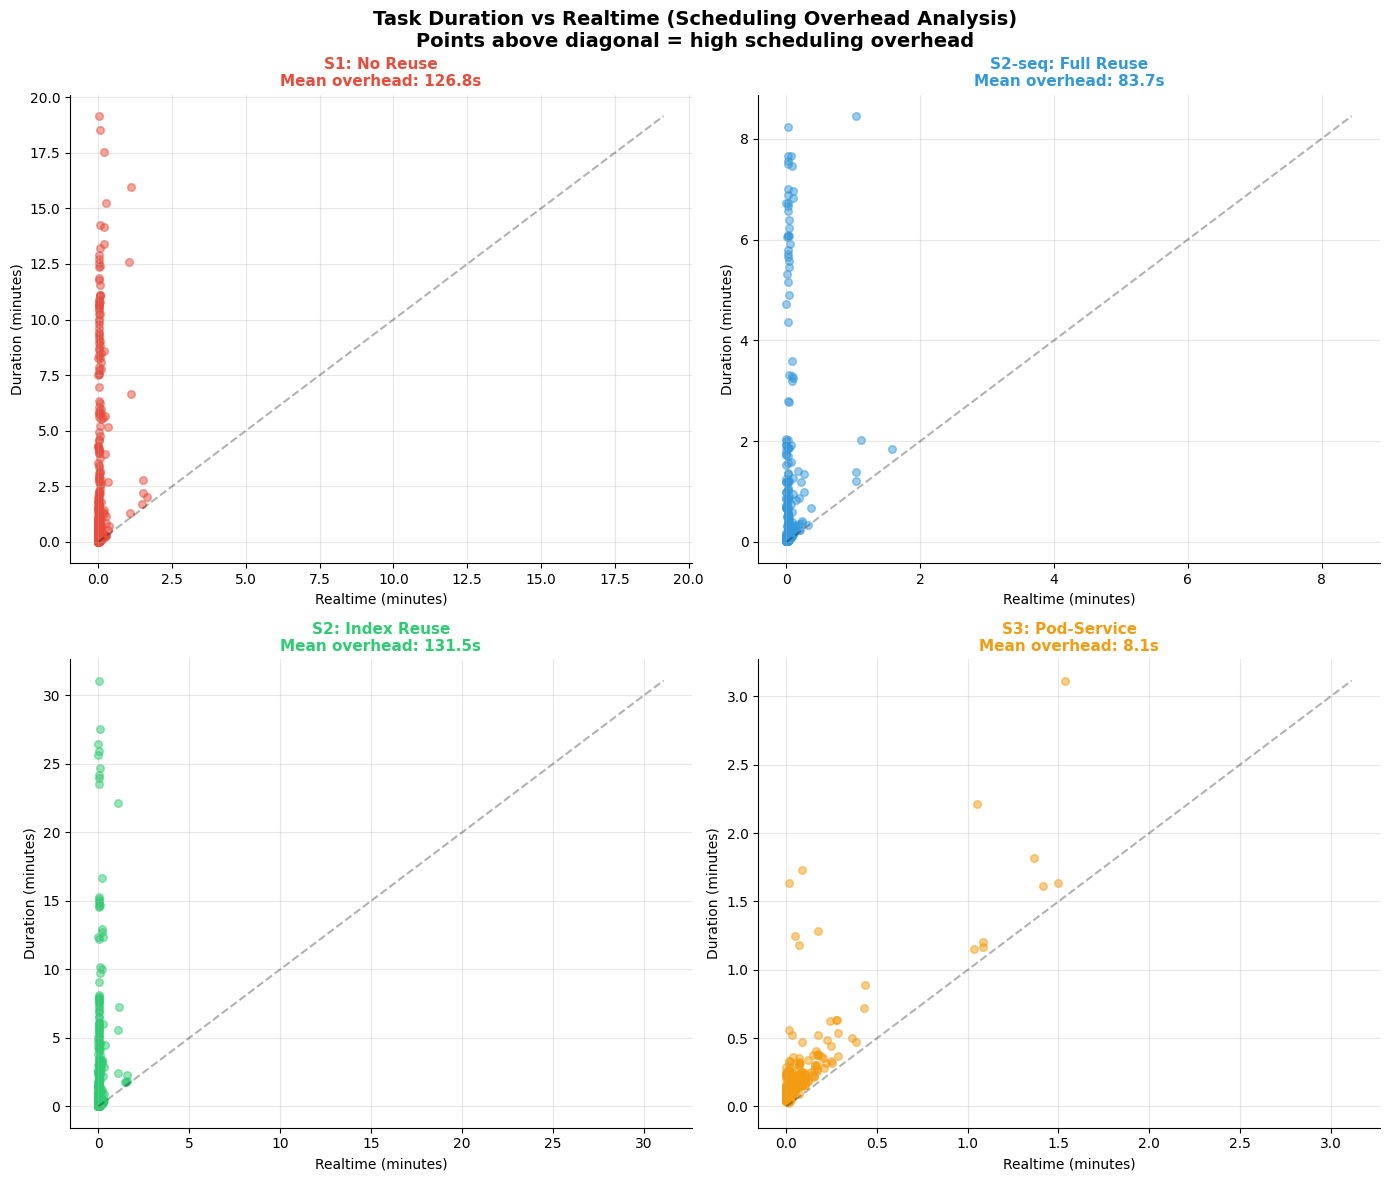

In [11]:
# ── Plot 10: Realtime vs Duration scatter — overhead analysis ─────────
# Duration includes queue/wait time; realtime is actual execution
# Gap = scheduling overhead. Shows if reuse reduces overhead

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Task Duration vs Realtime (Scheduling Overhead Analysis)\n'
             'Points above diagonal = high scheduling overhead',
             fontsize=14, fontweight='bold')
axes_flat = axes.flatten()

for ax, (exp_label, df) in zip(axes_flat, traces.items()):
    d = df[df['duration_sec'] > 0].copy()
    ax.scatter(d['realtime_sec']/60, d['duration_sec']/60,
               alpha=0.5, color=EXP_COLORS[exp_label], s=30)
    
    max_val = max(d['duration_sec'].max(), d['realtime_sec'].max()) / 60
    ax.plot([0, max_val], [0, max_val], 'k--', alpha=0.3, label='No overhead')
    
    # Calculate mean overhead
    overhead = (d['duration_sec'] - d['realtime_sec']).mean()
    ax.set_title(f'{exp_label}\nMean overhead: {overhead:.1f}s', 
                fontsize=11, fontweight='bold', color=EXP_COLORS[exp_label])
    ax.set_xlabel('Realtime (minutes)', fontsize=10)
    ax.set_ylabel('Duration (minutes)', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/trace_plot10_overhead_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

=== Summary Statistics ===
                    Total Tasks  Total Duration (min)  Mean Task Duration (s)  Max Task Duration (min)  Mean CPU %  Mean Peak RSS (MB)  Total Disk Read (GB)  Total Disk Write (GB)  Mean Overhead (s)
Experiment                                                                                                                                                                                            
S1: No Reuse                438                954.06                  130.69                    19.15       78.83              236.09                  6.67                   2.08             126.80
S2-seq: Full Reuse          220                321.44                   87.67                     8.45       81.81              238.94                  3.42                   1.09              83.73
S2: Index Reuse             434                980.31                  135.53                    31.08       75.81              236.93                  6.65                   2.

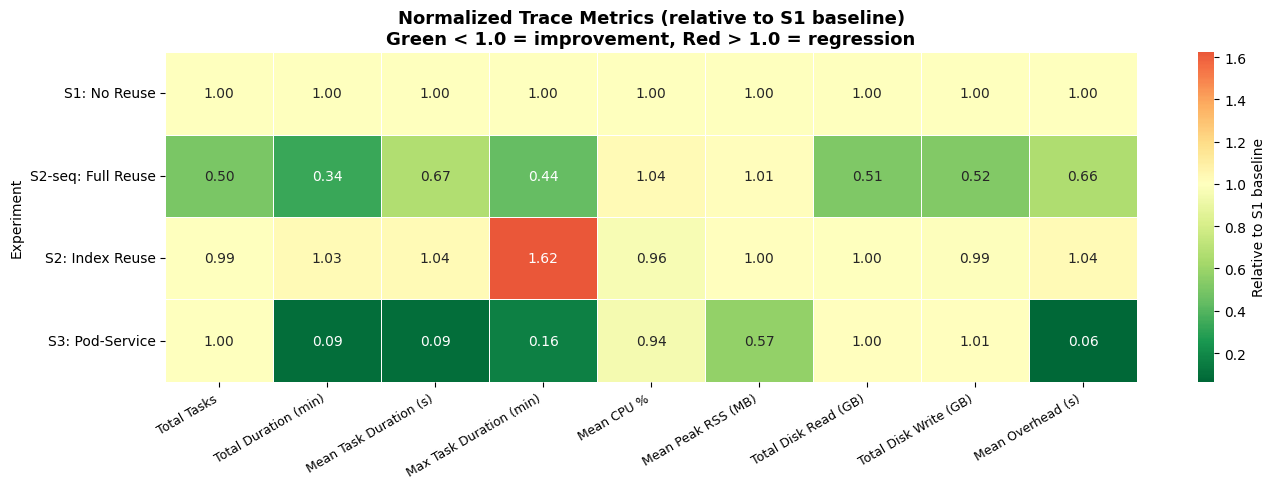

In [12]:
# ── Plot 11: Summary Statistics Table ─────────────────────────────────

summary_rows = []
for exp_label, df in traces.items():
    row = {
        'Experiment': exp_label,
        'Total Tasks': len(df),
        'Total Duration (min)': df['duration_sec'].sum() / 60,
        'Mean Task Duration (s)': df['duration_sec'].mean(),
        'Max Task Duration (min)': df['duration_sec'].max() / 60,
        'Mean CPU %': df['cpu_pct'].mean(),
        'Mean Peak RSS (MB)': df['peak_rss_mb'].mean(),
        'Total Disk Read (GB)': df['rchar_mb'].sum() / 1024,
        'Total Disk Write (GB)': df['wchar_mb'].sum() / 1024,
        'Mean Overhead (s)': (df['duration_sec'] - df['realtime_sec']).mean(),
    }
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index('Experiment')

# Calculate savings vs S1
baseline = summary_df.loc['S1: No Reuse']
savings_df = ((1 - summary_df.div(baseline)) * 100).round(1)
savings_df.columns = [f'{c} savings %' for c in savings_df.columns]

print('=== Summary Statistics ===')
print(summary_df.round(2).to_string())
print('\n=== Savings vs S1 Baseline (%) ===')
print(savings_df.to_string())

# Plot as heatmap
fig, ax = plt.subplots(figsize=(14, 5))
normalized = summary_df.div(summary_df.loc['S1: No Reuse'])
sns.heatmap(normalized, annot=True, fmt='.2f', cmap='RdYlGn_r',
            center=1.0, ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Relative to S1 baseline'})
ax.set_title('Normalized Trace Metrics (relative to S1 baseline)\n'
             'Green < 1.0 = improvement, Red > 1.0 = regression',
             fontsize=13, fontweight='bold')
plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig('/tmp/trace_plot11_summary_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ── Findings ──────────────────────────────────────────────────────────
print("""
=== FINDINGS FROM TRACE FILE ANALYSIS ===

Plot 1 — Total Pipeline Duration:
Shows the sum of all task durations across both users per setup. The per-user breakdown
reveals the asymmetry introduced by reuse: in S2-seq, User 2 has near-zero duration since
all tasks are served from Nextflow cache. In S2 and S3 (concurrent setups), both users run
similar workloads since reuse only affects specific steps. The total duration savings
reflect how much compute work each reuse strategy eliminates.

Plot 2 — Duration Heatmap per Step:
The most granular view of where time is spent. STAR_GENOMEGENERATE and BBMAP_BBSPLIT are
expected to disappear or halve in S2 (index reuse). STRINGTIE_STRINGTIE and FEATURECOUNTS
may show reduced duration in S3 (pod-service) due to warm service startup. S2-seq shows
all User 2 steps as zero. This plot directly validates that each reuse mechanism works
as intended for its target steps.

Plot 3 — Stacked Duration per Step:
Complements Plot 2 by showing totals rather than means. Steps like STAR_ALIGN and TRIMGALORE
dominate total compute time, making them primary targets for future reuse strategies.
The relative proportions of each step reveal where the pipeline spends most of its time
and where additional reuse could yield the greatest savings.

Plot 4 — CPU Utilization Heatmap:
Shows which steps are CPU-intensive. STAR_ALIGN and featureCounts tend to be high-CPU
tasks. If pod-service reuse (S3) changes CPU% for FEATURECOUNTS/STRINGTIE, it indicates
that the service pod handles requests differently than dedicated pods — potentially due
to serialization of concurrent requests via the service lock.

Plot 5 — Memory Heatmap:
Reveals memory footprint per step. STAR_GENOMEGENERATE is typically the most memory-hungry
step. S2 (index reuse) should show reduced memory pressure by running this step only once.
Steps with consistently high memory across all setups are candidates for memory optimization.

Plot 6 — Disk I/O Heatmap:
Reads and writes per step. Steps that write large intermediate files (STAR_ALIGN, SAMTOOLS)
should show the same I/O in S1/S2/S3 but reduced I/O in S2-seq since User 2's work
is cached and never written to disk. Network-heavy steps pulling reference data will show
reduced read I/O in S2 (shared index already on disk).

Plot 7 — Task Counts per Step:
The most direct evidence of reuse working. In S2 (index reuse), STAR_GENOMEGENERATE should
appear only once (vs twice in S1) since both users share the pre-built index. In S3
(pod-service), FEATURECOUNTS and STRINGTIE_STRINGTIE task counts should be zero since these
are replaced by HTTP service calls, not Nextflow tasks. In S2-seq, User 2 task counts
should be zero across all steps.

Plot 8 — Duration Distribution Box Plots:
Shows the spread and outliers of task durations. A narrower distribution indicates more
uniform task execution. Outliers are typically long-running steps like genome indexing.
Reuse strategies that eliminate these long-running outliers will visibly reduce the upper
whisker and shift the median downward.

Plot 9 — Top 10 Slowest Steps:
Per-experiment breakdown of the most time-consuming steps. Highlights which steps are
bottlenecks in each setup. If a step disappears from the top-10 in S2/S3 compared to S1,
it confirms that reuse successfully eliminated that bottleneck for the corresponding setup.

Plot 10 — Scheduling Overhead Scatter:
The gap between duration (wall clock including queue time) and realtime (pure execution time)
represents Kubernetes pod scheduling overhead. In S3 (pod-service), FEATURECOUNTS and
STRINGTIE tasks are replaced by lightweight HTTP requests in existing pods, so their
scheduling overhead drops to near zero. This plot quantifies how much of the pipeline
runtime is pure computation vs infrastructure overhead.

Plot 11 — Summary Heatmap:
A one-page overview of all key trace metrics normalized to S1. Green cells confirm
improvement across multiple dimensions simultaneously. The ideal reuse strategy shows
green across all columns. This is the most useful figure for paper presentation as it
concisely demonstrates the multi-dimensional impact of each reuse approach.
""")